# Whisper large-v3-turbo: speech recognition inference (CPU)

Transcribes speech from **(a) small English and Tagalog datasets with reference transcripts**, **(b) your microphone** and **(c) your own audio files**.
This notebook is inference only; LoRA fine-tuning is a training job, best done on a GPU (e.g. the HPC).

| | |
|---|---|
| Model | `openai/whisper-large-v3-turbo` (809M parameters, MIT license) |
| Runs on CPU? | **Yes.** About 3.5 GB of RAM in float32. Each clip of up to 30 s takes ~20–25 s (Whisper always processes a full 30 s window), and long audio runs at about 1.4× real time. A GPU is used automatically if present. |
| float32 vs bfloat16 | On this CPU **float32 was 2× faster** than bfloat16, so float32 is the default here. On a GPU, use float16. |
| Microphone | Recorded with PulseAudio's `parecord`. In WSL, WSLg forwards the Windows microphone as the source `RDPSource`. |

> **What it does:** Whisper is OpenAI's speech recognition model, trained on ~5 million hours of labelled audio in ~100 languages.
> An **encoder** turns 30 s of audio (as a log-Mel spectrogram) into features, and a **decoder** writes the text token by token,
> like a language model. **Turbo** is large-v3 with the decoder cut from 32 layers to 4, so it is several times faster with only slightly lower accuracy.
> The model can **transcribe** (text in the spoken language), **detect the language**, and add **timestamps**.
> ⚠ **Turbo does not translate:** it was fine-tuned on transcription only, so `task="translate"` mostly returns the original language
> (shown in section 1b). For speech → English translation use `openai/whisper-large-v3`, `medium` or `small`.
>
> | | |
> |---|---|
> | **Input** | audio as a waveform array + sampling rate (resampled to 16 kHz), or an audio file (wav/mp3/m4a/flac…, decoded with ffmpeg). Audio longer than 30 s is split into 30 s chunks automatically. |
> | **Output** | `{"text": "..."}`; with `return_timestamps=True`, also `"chunks": [{"timestamp": (0.0, 5.3), "text": "..."}, …]` |
> | **Options** | `language="en"` / `"tl"` / … (default: auto-detect), `task="transcribe"` (`"translate"` exists but turbo ignores it, see above) |
> | **Needs from you** | just the audio. `ffmpeg` is needed to read compressed files such as mp3/m4a. |
>
> **Example (librispeech_01):** `Mr. Quilter is the apostle of the middle classes, and we are glad to welcome his gospel.`
> The reference is `MISTER QUILTER IS THE APOSTLE OF THE MIDDLE CLASSES AND WE ARE GLAD TO WELCOME HIS GOSPEL`, an exact match after normalising.

In [1]:
import os, subprocess, sys, time, warnings
from pathlib import Path

import jiwer
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
import torch
from IPython.display import Audio, display
from scipy.signal import resample_poly
from transformers import AutoModelForSpeechSeq2Seq, AutoProcessor, pipeline
from transformers.utils import logging as hf_logging

warnings.filterwarnings("ignore"); hf_logging.set_verbosity_error()
# Jupyter kernels don't always have the conda env's bin/ on PATH; parecord, pactl and ffmpeg live there
os.environ["PATH"] = str(Path(sys.prefix) / "bin") + os.pathsep + os.environ["PATH"]

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "| torch", torch.__version__, "| threads", torch.get_num_threads())
DATA = Path("data"); OUT = Path("outputs"); OUT.mkdir(exist_ok=True)

device: cpu | torch 2.15.0+cpu | threads 4


## Settings

In [2]:
MODEL_ID = "openai/whisper-large-v3-turbo"   # smaller/faster alternatives: "openai/whisper-small", "openai/whisper-base"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32
LANGUAGE = None          # None = auto-detect; or e.g. "en", "tl" (Tagalog), "ja", "es"
MIC_SECONDS = 8          # length of each microphone recording
MIC_DEVICE = "RDPSource" # WSLg's Windows microphone; on native Linux use None for the default source
SILENCE_RMS = 0.003      # recordings quieter than this are treated as silence and not transcribed
MAX_NEW_TOKENS = 220     # backstop against runaway repetition (Whisper's limit is 448 tokens per 30 s window)
MY_AUDIO = Path("my_audio")   # put your own .wav/.mp3/.m4a/.flac files here (section 5)

## Load the model

In [3]:
t = time.time()
model = AutoModelForSpeechSeq2Seq.from_pretrained(MODEL_ID, dtype=DTYPE, low_cpu_mem_usage=True, attn_implementation="sdpa").to(DEVICE).eval()
processor = AutoProcessor.from_pretrained(MODEL_ID)
asr = pipeline("automatic-speech-recognition", model=model, tokenizer=processor.tokenizer,
               feature_extractor=processor.feature_extractor, dtype=DTYPE, device=DEVICE)
print(f"{MODEL_ID}: {sum(p.numel() for p in model.parameters()) / 1e6:.0f}M params, loaded in {time.time() - t:.1f}s")

SR = processor.feature_extractor.sampling_rate   # 16000

def load_audio(path):
    audio, sr = sf.read(path, dtype="float32", always_2d=True)
    audio = audio.mean(axis=1)                    # stereo -> mono
    if sr != SR:
        audio = resample_poly(audio, SR, sr).astype("float32")
    return audio

def transcribe(audio, task="transcribe", language=LANGUAGE, timestamps=False):
    gen = {"task": task, "max_new_tokens": MAX_NEW_TOKENS}
    if language: gen["language"] = language
    t = time.time()
    out = asr({"raw": audio, "sampling_rate": SR}, return_timestamps=timestamps, generate_kwargs=gen)
    out["seconds"] = time.time() - t
    return out

LANG_IDS = {tok_id: tok.strip("<|>") for tok, tok_id in model.generation_config.lang_to_id.items()}   # 100 languages

def detect_language(audio, top=3):
    feats = processor(audio[: 30 * SR], sampling_rate=SR, return_tensors="pt").input_features.to(DEVICE, DTYPE)
    with torch.no_grad():
        logits = model(input_features=feats, decoder_input_ids=torch.tensor([[model.config.decoder_start_token_id]], device=DEVICE)).logits[0, -1]
    probs = torch.softmax(logits[list(LANG_IDS)].float(), dim=0)   # compare only the language tokens
    best = probs.topk(top)
    codes = list(LANG_IDS.values())
    return [(codes[i], round(float(p), 3)) for p, i in zip(best.values, best.indices)]

import gzip
def looks_repetitive(text, threshold=2.4):
    # Whisper's own hallucination check: highly compressible text = the same phrase repeated over and over
    b = text.strip().encode()
    return len(b) > 40 and len(b) / len(gzip.compress(b)) > threshold

normalize = processor.tokenizer.normalize   # Whisper's English text normaliser ("Mr." -> "mister", drops punctuation, ...)

Loading weights:   0%|          | 0/587 [00:00<?, ?it/s]

openai/whisper-large-v3-turbo: 809M params, loaded in 8.5s


## 1. Dataset: LibriSpeech (10 clips with reference transcripts)

These are English audiobook recordings (LibriSpeech "clean" validation set). Each clip has a human transcript,
so we can compute the **word error rate (WER)**: the share of words substituted, deleted or inserted. 0% is perfect.
Both texts are normalised first (lowercase, no punctuation, "Mr." → "mister"), so formatting differences don't count as errors.

In [4]:
REFS = pd.read_csv(DATA / "references.csv").fillna("")
rows = []
for r in REFS[REFS.file.str.startswith("librispeech")].itertuples():
    audio = load_audio(DATA / r.file)
    out = transcribe(audio, language=LANGUAGE or "en")
    wer = jiwer.wer(normalize(r.reference), normalize(out["text"]))
    rows.append({"file": r.file, "audio s": r.seconds, "whisper": out["text"].strip(), "reference": r.reference,
                 "WER %": round(100 * wer, 1), "seconds": round(out["seconds"], 1)})
    print(f"{r.file}: {out['seconds']:.1f}s  WER {100 * wer:.1f}%", flush=True)
DS = pd.DataFrame(rows)
DS.to_csv(OUT / "librispeech_transcripts.csv", index=False)

total_wer = jiwer.wer([normalize(x) for x in DS.reference], [normalize(x) for x in DS.whisper])
print(f"\noverall WER: {100 * total_wer:.2f}%  |  {DS['audio s'].sum():.0f}s of audio in {DS.seconds.sum():.0f}s "
      f"(real-time factor {DS.seconds.sum() / DS['audio s'].sum():.2f}; below 1 = faster than real time)")
pd.set_option("display.max_colwidth", 120)
display(DS[["file", "audio s", "WER %", "seconds", "whisper", "reference"]])

librispeech_01.wav: 24.0s  WER 0.0%
librispeech_02.wav: 28.3s  WER 0.0%
librispeech_03.wav: 25.2s  WER 0.0%
librispeech_04.wav: 20.2s  WER 4.0%
librispeech_05.wav: 31.4s  WER 5.6%
librispeech_06.wav: 111.0s  WER 5.6%
librispeech_07.wav: 22.1s  WER 0.0%
librispeech_08.wav: 21.4s  WER 5.3%
librispeech_09.wav: 28.6s  WER 0.0%
librispeech_10.wav: 20.8s  WER 7.0%

overall WER: 3.86%  |  110s of audio in 333s (real-time factor 3.04; below 1 = faster than real time)


,file,audio s,WER %,seconds,whisper,reference
0,librispeech_01.wav,5.9,0.0,24.0,"Mr. Quilter is the apostle of the middle classes, and we are glad to welcome his gospel.",MISTER QUILTER IS THE APOSTLE OF THE MIDDLE CLASSES AND WE ARE GLAD TO WELCOME HIS GOSPEL
1,librispeech_02.wav,4.8,0.0,28.3,Nor is Mr. Quilter's manner less interesting than his matter.,NOR IS MISTER QUILTER'S MANNER LESS INTERESTING THAN HIS MATTER
2,librispeech_03.wav,12.5,0.0,25.2,"He tells us that at this festive season of the year, with Christmas and roast beef looming before us, similes drawn ...",HE TELLS US THAT AT THIS FESTIVE SEASON OF THE YEAR WITH CHRISTMAS AND ROAST BEEF LOOMING BEFORE US SIMILES DRAWN FR...
3,librispeech_04.wav,9.9,4.0,20.2,"He has grave doubts whether Sir Frederick Layton's work is really Greek after all, and can discover in it but little...",HE HAS GRAVE DOUBTS WHETHER SIR FREDERICK LEIGHTON'S WORK IS REALLY GREEK AFTER ALL AND CAN DISCOVER IN IT BUT LITTL...
4,librispeech_05.wav,29.4,5.6,31.4,"Linnell's pictures are a sort of Up Guards and Adam paintings, and Mason's exquisite idles are as national as a jing...",LINNELL'S PICTURES ARE A SORT OF UP GUARDS AND AT EM PAINTINGS AND MASON'S EXQUISITE IDYLLS ARE AS NATIONAL AS A JIN...
5,librispeech_06.wav,9.0,5.6,111.0,"It is obviously unnecessary for us to point out how luminous these criticisms are, how delicate an expression.",IT IS OBVIOUSLY UNNECESSARY FOR US TO POINT OUT HOW LUMINOUS THESE CRITICISMS ARE HOW DELICATE IN EXPRESSION
6,librispeech_07.wav,5.6,0.0,22.1,"On the general principles of art, Mr. Quilter writes with equal lucidity.",ON THE GENERAL PRINCIPLES OF ART MISTER QUILTER WRITES WITH EQUAL LUCIDITY
7,librispeech_08.wav,9.2,5.3,21.4,"Painting, he tells us, is of a different quality to mathematics and Finnish in art is adding more fact.",PAINTING HE TELLS US IS OF A DIFFERENT QUALITY TO MATHEMATICS AND FINISH IN ART IS ADDING MORE FACT
8,librispeech_09.wav,5.1,0.0,28.6,"As for etchings, they are of two kinds, British and foreign.",AS FOR ETCHINGS THEY ARE OF TWO KINDS BRITISH AND FOREIGN
9,librispeech_10.wav,18.3,7.0,20.8,he laments most bitterly the divorce that has been made between decorative art and what we usually call pictures mak...,HE LAMENTS MOST BITTERLY THE DIVORCE THAT HAS BEEN MADE BETWEEN DECORATIVE ART AND WHAT WE USUALLY CALL PICTURES MAK...


Listen to one clip and compare:

In [5]:
r = DS.iloc[2]
display(Audio(str(DATA / r.file)))
print("whisper  :", r.whisper)
print("reference:", r.reference)

whisper  : He tells us that at this festive season of the year, with Christmas and roast beef looming before us, similes drawn from eating and its results occur most readily to the mind.
reference: HE TELLS US THAT AT THIS FESTIVE SEASON OF THE YEAR WITH CHRISTMAS AND ROAST BEEF LOOMING BEFORE US SIMILES DRAWN FROM EATING AND ITS RESULTS OCCUR MOST READILY TO THE MIND


Where it differed from the reference (word by word):

In [6]:
for _, r in DS[DS["WER %"] > 0].iterrows():
    words = jiwer.process_words(normalize(r["reference"]), normalize(r["whisper"]))
    print(f"--- {r['file']} (WER {r['WER %']}%)")
    print(jiwer.visualize_alignment(words, show_measures=False)[:800], "\n")
if (DS["WER %"] == 0).all():
    print("No differences: every clip was transcribed exactly (after normalisation).")

--- librispeech_04.wav (WER 4.0%)
=== SENTENCE 1 ===

REF: he has grave doubts whether sir frederick leighton is work is really greek after all and can discover in it but little of rocky ithaca
HYP: he has grave doubts whether sir frederick   layton is work is really greek after all and can discover in it but little of rocky ithaca
                                                      S                                                                                    
 

--- librispeech_05.wav (WER 5.6%)
=== SENTENCE 1 ===

REF: linnell is pictures are a sort of up guards and   at em paintings and mason is exquisite idylls are as national as a jingo poem mister  birket foster is landscapes smile at one much in the same way that mister carker used to flash his teeth and mister john collier gives his sitter a cheerful slap on the back before he says like a shampooer in a turkish bath next man
HYP: linnell is pictures are a sort of up guards and adam ** paintings and mason is exquisite  

## 1b. Tagalog / Filipino (FLEURS, 10 clips with reference transcripts)

Whisper is multilingual. These clips are native speakers reading Filipino sentences, from Google's **FLEURS** dataset (`fil_ph` test set).
For each clip the notebook:
- **detects the language** (Whisper's code for Tagalog/Filipino is `tl`)
- **transcribes** with `language="tl"`, scored with **WER** against the reference. A *basic* normaliser is used (lowercase, no punctuation);
  the English one would wrongly rewrite Tagalog words.
- **translates** the first 3 clips into English (`task="translate"`)

**Results in this run:** every clip was detected as `tl` (0.99–1.00), with an overall **WER of 13.3%** (English: 3.9%).
The worst clip (50%) is the one with Indian names: "Lakkha Singh" → "Lakasing", "chhappan bhog" → "Chapan Bog".
Other errors are small spelling variants ("rehiyon" → "regyon", "gayundin" → "gayun din") and "20 porsiyento" written as "20%".

Expect a higher WER than English: Tagalog is a much smaller share of Whisper's training data, and these sentences contain
foreign names (Nyiragongo, Lakkha Singh, Schengen).

In [7]:
from transformers.models.whisper.english_normalizer import BasicTextNormalizer
basic_norm = BasicTextNormalizer()

rows = []
for r in REFS[REFS.file.str.startswith("tagalog")].itertuples():
    audio = load_audio(DATA / r.file)
    lang = detect_language(audio, top=2)
    out = transcribe(audio, language="tl")
    wer = jiwer.wer(basic_norm(r.reference), basic_norm(out["text"]))
    rows.append({"file": r.file, "audio s": r.seconds, "detected": f"{lang[0][0]} {lang[0][1]:.2f}", "WER %": round(100 * wer, 1),
                 "seconds": round(out["seconds"], 1), "whisper": out["text"].strip(), "reference": r.reference})
    print(f"{r.file}: detected {lang[0][0]} ({lang[0][1]:.2f}), WER {100 * wer:.1f}%, {out['seconds']:.1f}s", flush=True)
TL = pd.DataFrame(rows)
TL.to_csv(OUT / "tagalog_transcripts.csv", index=False)
TL_WER = jiwer.wer([basic_norm(x) for x in TL.reference], [basic_norm(x) for x in TL.whisper])
print(f"\nTagalog overall WER: {100 * TL_WER:.1f}%  |  {TL['audio s'].sum():.0f}s of audio in {TL.seconds.sum():.0f}s")
display(TL[["file", "detected", "WER %", "whisper", "reference"]])

tagalog_01.wav: detected tl (1.00), WER 0.0%, 19.6s
tagalog_02.wav: detected tl (1.00), WER 4.5%, 18.6s
tagalog_03.wav: detected tl (1.00), WER 3.6%, 19.5s
tagalog_04.wav: detected tl (0.99), WER 11.8%, 17.5s
tagalog_05.wav: detected tl (0.99), WER 7.1%, 20.3s
tagalog_06.wav: detected tl (1.00), WER 50.0%, 17.4s
tagalog_07.wav: detected tl (1.00), WER 20.0%, 20.7s
tagalog_08.wav: detected tl (0.99), WER 14.8%, 20.1s
tagalog_09.wav: detected tl (1.00), WER 13.3%, 22.1s
tagalog_10.wav: detected tl (0.99), WER 17.6%, 19.7s

Tagalog overall WER: 13.3%  |  140s of audio in 195s


,file,detected,WER %,whisper,reference
0,tagalog_01.wav,tl 1.00,0.0,"Anim na bihag, kabilang ang mga bata at matatanda, ang maagang pinakawalan, gayon din ang mga Pilipinong potograpo.","Anim na bihag, kabilang ang mga bata at matatanda, ang maagang pinakawalan, gayon din ang mga Pilipinong potograpo."
1,tagalog_02.wav,tl 1.00,4.5,Ang buong 20% ng tubig na lumalabas mula sa mga ilog sa planeta patungo sa mga dagat ay mula sa Amazon.,Ang buong 20 porsiyento ng tubig na lumalabas mula sa mga ilog sa planeta patungo sa mga dagat ay mula sa Amazon.
2,tagalog_03.wav,tl 1.00,3.6,Ang mga atom ng hydrogen ay binubuo lamang ng isang proton na hiwalay sa elektron nito. At ang hiwalay na ion ng hyd...,"Ang mga atom ng hydrogen ay binubuo lamang ng isang proton na hiwalay sa elekton nito, at ang hiwalay na ion ng hydr..."
3,tagalog_04.wav,tl 0.99,11.8,Sahel ang nasa hangganan ng regyon sa Hilaga at sa Tibog at Kanluran ay ang Karagatang Atlantiko.,"Sahel ang nasa hangganan ng rehiyon sa hilaga, at sa timog at kanluran ay ang Karagatang Atlantiko."
4,tagalog_05.wav,tl 0.99,7.1,"Noong 2002, nawasak ang goma dahil sa lahar mula sa bulkan ng Nyaragongo na tumakip ng karamihan sa mga kalsada ng b...",Noong 2002 nawasak ang Goma dahil sa lahar mula sa bulkan ng Nyiragongo na tumakip ng karamihan sa mga kalsada ng ba...
5,tagalog_06.wav,tl 1.00,50.0,Ipinresenta rin ni Lakasing ang Chapan Bog. Sinasamaan siya noon ng mga ngantang si Raju Candlewal.,Ipinresenta rin ni Lakkha Singh ang chhappan bhog. Sinasamahan siya noon ng mangangantang si Raju Khandelwal.
6,tagalog_07.wav,tl 1.00,20.0,"Ang mga opisyal na lingwahin ng Barcelona ay Katalan at Espanyol. Mga kalahati ang mas gustong magsalita ng Katalan,...",Ang mga opisyal na lengguwahe ng Barcelona ay Catalan at Espanyol. Mga kalahati ang mas gustong magsalita ng Catalan...
7,tagalog_08.wav,tl 0.99,14.8,"Sa ibang mga ruta, ang mas malalaki mga kumpanya ay mayroong sariling mga aeroplano. Ngunit sa ibang mga ruta at mas...","Sa ibang mga ruta, ang mas malalaking mga kompanya ay mayroong sariling mga eroplano, ngunit sa ibang mga ruta at ma..."
8,tagalog_09.wav,tl 1.00,13.3,"Gayun din naman, sa pagkakaroon ng Schengen Visa, hindi mo kailangan mag-apply ng visa ng hiwalay sa bawat bansang m...","Gayundin naman, sa pagkakaroon ng Schengen visa, hindi mo kailangang mag-apply ng visa nang hiwalay sa bawat bansang..."
9,tagalog_10.wav,tl 0.99,17.6,Mas maliit ang bilang ng ROSB. Mas hindi gaano aktibo ang bituin kaugnay ng mga magnetikong pagbabaliktad.,"Mas maliit ang bilang na Rosby, mas hindi gaanong aktibo ang bituin kaugnay ng mga magnetikong pagbabaliktad."


Listen and compare one clip, with the word-by-word differences:

In [8]:
r = TL.sort_values("WER %").iloc[len(TL) // 2]   # a typical (median) clip
display(Audio(str(DATA / r.file)))
print(jiwer.visualize_alignment(jiwer.process_words(basic_norm(r.reference), basic_norm(r.whisper)), show_measures=False)[:900])

=== SENTENCE 1 ===

REF: ***** gayundin naman sa pagkakaroon ng schengen visa hindi mo kailangang mag apply ng visa nang hiwalay sa bawat bansang miyembro ng schengen kaya nakakatipid ng oras pera at asikasuhing papeles
HYP: gayun      din naman sa pagkakaroon ng schengen visa hindi mo  kailangan mag apply ng visa   ng hiwalay sa bawat bansang miyembro ng schengen kaya nakakatipid ng oras pera at asikasuhing papeles
         I        S                                                         S                      S                                                                                                   



**Translation to English** (`task="translate"`), first 3 clips. **This shows a limitation:** large-v3-turbo was fine-tuned on
transcription only, so it returns Tagalog instead of English (and once turned "Anim" into "6."). For translation, set `MODEL_ID` to
`openai/whisper-large-v3` (slower: 32 decoder layers instead of 4) or `openai/whisper-medium` and re-run.

In [9]:
for r in TL.head(3).itertuples():
    en = transcribe(load_audio(DATA / r.file), task="translate", language="tl")
    print(f"{r.file}\n  Tagalog : {r.whisper}\n  English : {en['text'].strip()}  ({en['seconds']:.1f}s)\n")

tagalog_01.wav
  Tagalog : Anim na bihag, kabilang ang mga bata at matatanda, ang maagang pinakawalan, gayon din ang mga Pilipinong potograpo.
  English : 6. Kabilang ang mga bata at matatanda, ang maagang pinakawalan, gayon din ang mga Pilipinong potograpo.  (17.6s)

tagalog_02.wav
  Tagalog : Ang buong 20% ng tubig na lumalabas mula sa mga ilog sa planeta patungo sa mga dagat ay mula sa Amazon.
  English : Ang buong dalawampung porsyento ng tubig na lumalabas mula sa mga ilog sa planeta patungo sa mga dagat ay mula sa Amazon.  (19.9s)

tagalog_03.wav
  Tagalog : Ang mga atom ng hydrogen ay binubuo lamang ng isang proton na hiwalay sa elektron nito. At ang hiwalay na ion ng hydrogen ay karaniwang tinatawag na proton.
  English : Ang mga atom ng hydrogen ay binubuo lamang ng isang proton na hiwalay sa elektron nito. At ang hiwalay na ion ng hydrogen ay karaniwang tinatawag na proton.  (181.0s)



## 2. Long audio with timestamps (62 s)

Audio longer than 30 s is cut into 30 s windows and the pieces are joined. With `return_timestamps=True`, Whisper also
returns **segment timestamps** (start and end in seconds for each sentence-like chunk).
Word-level timestamps (`return_timestamps="word"`) also exist, but they ran out of memory on this 7 GB laptop, so use them on a GPU.

In [10]:
long_audio = load_audio(DATA / "long_62s.wav")
display(Audio(long_audio, rate=SR))
out = transcribe(long_audio, language=LANGUAGE or "en", timestamps=True)
print(f"{len(long_audio) / SR:.1f}s of audio transcribed in {out['seconds']:.1f}s\n")
LONG_S = out["seconds"]
SEG = pd.DataFrame([{"start": c["timestamp"][0], "end": c["timestamp"][1], "text": c["text"].strip()}
                    for c in out["chunks"] if c["text"].strip()])   # drop empty pieces at 30 s chunk boundaries
SEG.to_csv(OUT / "long_62s_segments.csv", index=False)
display(SEG)

62.5s of audio transcribed in 66.9s



,start,end,text
0,0.00,5.30,"Mr. Quilter is the apostle of the middle classes, and we are glad to welcome his gospel."
1,6.36,10.08,Nor is Mr. Quilter's manner less interesting than his matter.
2,11.04,17.62,"He tells us that at this festive season of the year, with Christmas and roast beef looming before us,"
3,18.46,22.60,similes drawn from eating and its results occur most readily to the mind.
4,23.10,28.68,"He has grave doubts whether Sir Frederick Layton's work is really Greek after all,"
5,32.48,33.66,and can discover in it but little of rocky Ithaca.
6,37.84,38.24,"Linnell's pictures are a sort of Up Guards and Adam paintings,"
7,42.86,44.50,and Mason's exquisite idles are as national as a jingo poem.
8,47.64,51.56,"Mr. Birkett Foster's landscapes smile at one much in the same way that Mr. Carker used to flash his teeth,"
9,52.40,57.24,and Mr. John Collier gives his sitter a cheerful slap on the back


## 3. Your microphone

`record()` records `MIC_SECONDS` seconds from the microphone, plays it back, draws the waveform,
**detects the language**, and transcribes it (plus a `translate` attempt, which turbo usually ignores).

- **Run the cell, then start speaking.** The recording starts immediately.
- Try speaking another language (e.g. Tagalog) to see language detection and transcription.
- Windows may need microphone access enabled for WSL. If the waveform is flat, check *Settings → Privacy → Microphone*.
- **No one was speaking when this notebook was saved,** so the saved output below is just room noise.
- **Hallucinations:** on silence or noise, Whisper tends to invent text, most often "Thank you.", sometimes repeated over and over.
  This is a known Whisper behaviour. The notebook has two guards:
  - recordings quieter than `SILENCE_RMS` are skipped entirely;
  - output that repeats itself (gzip compression ratio > 2.4, Whisper's own rule) is flagged and cut short.

  A single short invented phrase on background noise can't be detected reliably. Turbo's built-in "no speech" score was 0 on both noise and speech in testing, so it isn't used.

recording 8s ... speak now
done: 7.5s, level (RMS) 0.0773


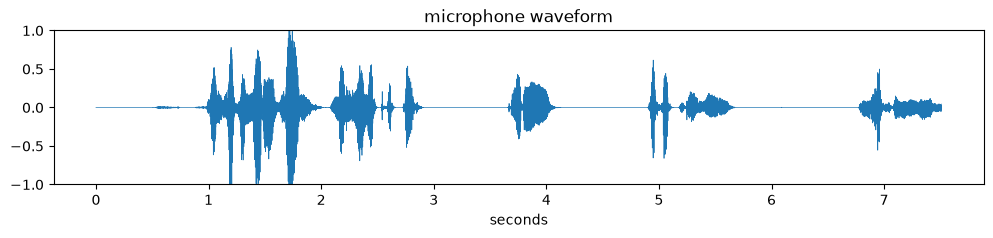

detected language (top 3): [('tl', 0.983), ('en', 0.013), ('id', 0.001)]
transcript (76.1s): Nasa ka na Rizal, hinahanap kita. Pero bakit ganun ang aking iniibig?
translate task (turbo usually returns the original language) (19.9s): Nasa ka narizal na hanap kita, pero bakit ganun ang aking iniibig?


In [11]:
def record(seconds=MIC_SECONDS, path=OUT / "mic_recording.wav"):
    cmd = ["parecord", f"--rate={SR}", "--channels=1", "--format=s16le", "--file-format=wav", str(path)]
    if MIC_DEVICE: cmd.insert(1, f"--device={MIC_DEVICE}")
    print(f"recording {seconds}s ... speak now", flush=True)
    proc = subprocess.Popen(cmd)
    time.sleep(seconds); proc.terminate(); proc.wait()
    audio = load_audio(path)
    print(f"done: {len(audio) / SR:.1f}s, level (RMS) {np.sqrt(np.mean(audio ** 2)):.4f}")
    return audio

def mic_demo(seconds=MIC_SECONDS):
    audio = record(seconds)
    display(Audio(audio, rate=SR))
    plt.figure(figsize=(12, 2))
    plt.plot(np.arange(len(audio)) / SR, audio, lw=0.5)
    plt.xlabel("seconds"); plt.ylim(-1, 1); plt.title("microphone waveform"); plt.show()
    level = float(np.sqrt(np.mean(audio ** 2)))
    if level < SILENCE_RMS:
        print(f"Recording is silent (RMS {level:.4f} < SILENCE_RMS {SILENCE_RMS}). Nothing transcribed. "
              "Speak closer to the mic, check Windows microphone access, or lower SILENCE_RMS.")
        return ""
    langs = detect_language(audio)
    print("detected language (top 3):", langs)
    tr = transcribe(audio)
    en = transcribe(audio, task="translate", language=langs[0][0])
    for label, r in [("transcript", tr), ("translate task (turbo usually returns the original language)", en)]:
        text = r["text"].strip()
        if looks_repetitive(text):
            print(f"{label} ({r['seconds']:.1f}s): WARNING: repetitive output, likely a hallucination (no clear speech?). Start: {text[:80]!r}")
        else:
            print(f"{label} ({r['seconds']:.1f}s):", text)
    return tr["text"]

mic_text = mic_demo()

Run this cell again (or call `mic_demo(15)` for a longer recording) as many times as you like.

## 4. Language detection and translation on the dataset

The same detection on a LibriSpeech clip (English), and the `translate` task. For English speech, translate simply returns the transcript.

In [12]:
audio = load_audio(DATA / "librispeech_03.wav")
print("detected:", detect_language(audio))
print("translate:", transcribe(audio, task="translate", language="en")["text"].strip())

detected: [('en', 1.0), ('es', 0.0), ('de', 0.0)]


translate: he tells us that at this festive season of the year with christmas and roast beef looming before us similes drawn from eating and its results occur most readily to the mind


## 5. Your own audio files

Put any audio files (`.wav .mp3 .m4a .flac .ogg`) in `my_audio/` and run the cell. mp3/m4a are decoded with ffmpeg.
Results are saved to `outputs/my_audio_transcripts.csv`.

In [13]:
MY_AUDIO.mkdir(exist_ok=True)
files = sorted(p for p in MY_AUDIO.iterdir() if p.suffix.lower() in {".wav", ".mp3", ".m4a", ".flac", ".ogg"})
if not files:
    print(f"No files in {MY_AUDIO}/ yet. Add some and re-run this cell.")
rows = []
for f in files:
    t = time.time()
    out = asr(str(f), return_timestamps=True, generate_kwargs={"language": LANGUAGE} if LANGUAGE else {})
    rows.append({"file": f.name, "seconds": round(time.time() - t, 1), "text": out["text"].strip()})
    print(f"{f.name} ({rows[-1]['seconds']}s): {rows[-1]['text'][:300]}")
if rows:
    pd.DataFrame(rows).to_csv(OUT / "my_audio_transcripts.csv", index=False)

No files in my_audio/ yet. Add some and re-run this cell.


## 6. Summary

In [14]:
summary = pd.DataFrame([
    {"input": "LibriSpeech (10 clips)", "audio s": DS["audio s"].sum(), "processing s": DS.seconds.sum(), "WER %": round(100 * total_wer, 2)},
    {"input": "long clip (timestamps)", "audio s": round(len(long_audio) / SR, 1), "processing s": round(LONG_S, 1), "WER %": None},
    {"input": "Tagalog FLEURS (10 clips)", "audio s": TL["audio s"].sum(), "processing s": TL.seconds.sum(), "WER %": round(100 * TL_WER, 2)},
])
summary["real-time factor"] = (summary["processing s"] / summary["audio s"]).round(2)
print(f"model: {MODEL_ID} | device: {DEVICE} | dtype: {DTYPE}")
display(summary)
summary.to_csv(OUT / "summary.csv", index=False)
print("real-time factor = processing time / audio length; below 1 means faster than real time")
print("saved:", *sorted(str(p) for p in OUT.iterdir()), sep="\n  ")

model: openai/whisper-large-v3-turbo | device: cpu | dtype: torch.float32


,input,audio s,processing s,WER %,real-time factor
0,LibriSpeech (10 clips),109.7,162.5,3.86,1.48
1,long clip (timestamps),62.5,66.9,NaN,1.07
2,Tagalog FLEURS (10 clips),140.5,196.8,13.30,1.40


real-time factor = processing time / audio length; below 1 means faster than real time
saved:
  outputs/librispeech_transcripts.csv
  outputs/long_62s_segments.csv
  outputs/mic_recording.wav
  outputs/summary.csv
  outputs/tagalog_transcripts.csv
